In [1]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# read in the cleaned CSV with data from central valley stations
path = 'D:/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
if os.path.exists(path):
    CV_rows = pd.read_csv(path, low_memory = False)
else:
    path = '/Volumes/disk1/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
    CV_rows = pd.read_csv(path, low_memory = False)

print(CV_rows)

           STATION_ID         STATION                 DATE  year  month  day  \
0         USW00023155  BAKERSFIELD AP  1928-01-01 02:00:00  1928      1    1   
1         USW00023155  BAKERSFIELD AP  1928-01-01 05:00:00  1928      1    1   
2         USW00023155  BAKERSFIELD AP  1928-01-01 08:00:00  1928      1    1   
3         USW00023155  BAKERSFIELD AP  1928-01-01 09:00:00  1928      1    1   
4         USW00023155  BAKERSFIELD AP  1928-01-01 11:00:00  1928      1    1   
...               ...             ...                  ...   ...    ...  ...   
10131269  USW00023202  TRAVIS FLD AFB  2026-09-28 02:55:00  2026      9   28   
10131270  USW00023202  TRAVIS FLD AFB  2026-09-28 03:55:00  2026      9   28   
10131271  USW00023202  TRAVIS FLD AFB  2026-09-28 04:55:00  2026      9   28   
10131272  USW00023202  TRAVIS FLD AFB  2026-09-28 05:55:00  2026      9   28   
10131273  USW00023202  TRAVIS FLD AFB  2026-09-28 06:55:00  2026      9   28   

          hour  minute  LATITUDE  LONGI

In [3]:
#Remove duplicate hours for each station
CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

print(CV_rows.shape)

(8172697, 16)


In [4]:
# Drop SACRAMENTO MATHER AFB from CV_rows
CV_rows = CV_rows[CV_rows['STATION'] != 'SACRAMENTO MATHER AFB']

In [5]:
# Exclude days from April through October (months 4-10) in CV_rows
CV_rows = CV_rows[~CV_rows['month'].isin([4, 5, 6, 7, 8, 9, 10])]

print("CV_rows after removing April-October:", CV_rows.shape)

CV_rows after removing April-October: (3117146, 16)


In [6]:
# Exclude the year 2026
CV_rows = CV_rows[CV_rows['year'] != 2026]

print("CV_data after removing year 2026:", CV_rows.shape)

CV_data after removing year 2026: (3092881, 16)


In [7]:
CV_precip_rows = CV_rows[CV_rows['HourlyPrecipitation'] >= 0.03]

In [8]:
# Show CV_precip_rows
CV_precip_rows

,STATION_ID,STATION,DATE,year,month,day,hour,minute,LATITUDE,LONGITUDE,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyWindDirection,HourlyWindSpeed,HourlyPrecipitation,HourlyVisibility
168536,USW00023155,BAKERSFIELD AP,1948-12-03 15:00:00,1948,12,3,15,0,35.4342,-119.0553,6.1,4.4,360.0,8.2,1.5,9.600
168537,USW00023155,BAKERSFIELD AP,1948-12-03 16:00:00,1948,12,3,16,0,35.4342,-119.0553,6.1,3.9,90.0,3.6,0.8,16.000
168542,USW00023155,BAKERSFIELD AP,1948-12-03 21:00:00,1948,12,3,21,0,35.4342,-119.0553,5.6,4.4,225.0,3.6,0.3,16.000
168599,USW00023155,BAKERSFIELD AP,1948-12-06 06:00:00,1948,12,6,6,0,35.4342,-119.0553,6.7,6.1,315.0,3.6,0.5,4.800
168600,USW00023155,BAKERSFIELD AP,1948-12-06 07:00:00,1948,12,6,7,0,35.4342,-119.0553,6.7,5.6,270.0,3.6,1.3,6.400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10123666,USW00023202,TRAVIS FLD AFB,2025-12-25 19:55:00,2025,12,25,19,55,38.2667,-121.9333,12.0,10.2,180.0,4.1,3.0,16.000
10123667,USW00023202,TRAVIS FLD AFB,2025-12-25 20:55:00,2025,12,25,20,55,38.2667,-121.9333,12.0,10.4,220.0,4.1,3.3,6.437
10123668,USW00023202,TRAVIS FLD AFB,2025-12-25 21:55:00,2025,12,25,21,55,38.2667,-121.9333,11.7,10.3,160.0,5.1,4.8,16.000
10123913,USW00023202,TRAVIS FLD AFB,2025-12-31 16:55:00,2025,12,31,16,55,38.2667,-121.9333,9.2,8.0,30.0,4.6,0.2,14.484


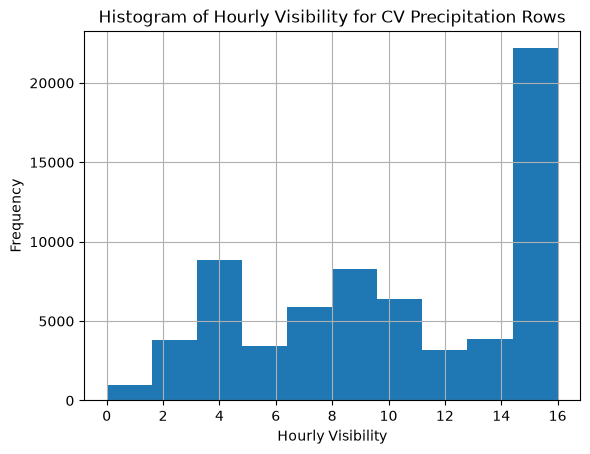

In [9]:
#Display histogram of visibility data from CV_precip_rows
CV_precip_rows['HourlyVisibility'].hist()
plt.xlabel('Hourly Visibility')
plt.ylabel('Frequency')
plt.title('Histogram of Hourly Visibility for CV Precipitation Rows')
plt.show()

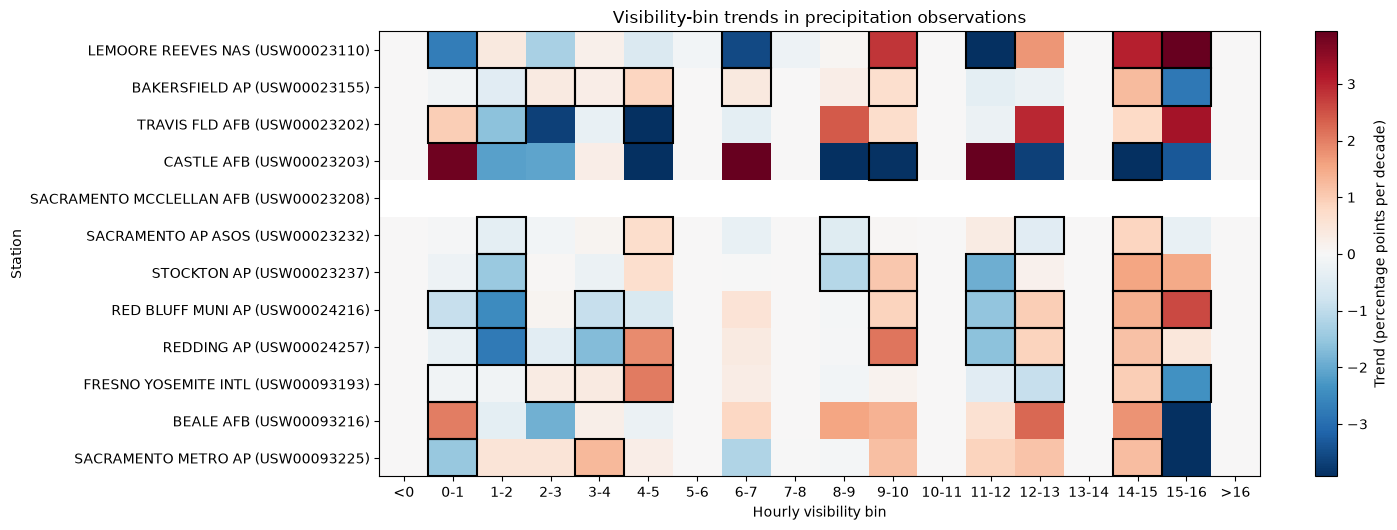

In [10]:
# Assign visibility bins: <0, 0-1, ..., 15-16, >16
bin_labels = ['<0'] + [f'{i}-{i+1}' for i in range(16)] + ['>16']

plot_data = CV_precip_rows.dropna(
    subset=['HourlyVisibility', 'year', 'STATION_ID']
).copy()

plot_data['VisibilityBin'] = pd.cut(
    plot_data['HourlyVisibility'],
    bins=[-np.inf] + list(range(17)) + [np.inf],
    labels=bin_labels,
    right=False
)

# Include exactly 16 in the 15-16 bin
plot_data.loc[plot_data['HourlyVisibility'] == 16, 'VisibilityBin'] = '15-16'

station_groups = plot_data.groupby(
    ['STATION_ID', 'STATION'], dropna=False, sort=True

)

station_labels = []
slopes = []
p_values = []

for (station_id, station_name), station_data in station_groups:
    station_labels.append(f'{station_name} ({station_id})')

    annual_totals = station_data.groupby('year').size().sort_index()
    annual_bin_counts = (
        station_data.groupby(['year', 'VisibilityBin'], observed=False)
        .size()
        .unstack(fill_value=0)
        .reindex(index=annual_totals.index, columns=bin_labels, fill_value=0)
    )

    annual_percent = annual_bin_counts.div(annual_totals, axis=0) * 100
    station_slopes = []
    station_p_values = []

    for bin_label in bin_labels:
        if len(annual_percent) >= 2:
            result = stats.linregress(
                annual_percent.index.to_numpy(dtype=float),
                annual_percent[bin_label].to_numpy(dtype=float)
            )
            station_slopes.append(result.slope * 10)  # percentage points per decade
            station_p_values.append(result.pvalue)
        else:
            station_slopes.append(np.nan)
            station_p_values.append(np.nan)

    slopes.append(station_slopes)
    p_values.append(station_p_values)

slope_matrix = np.asarray(slopes, dtype=float)
p_matrix = np.asarray(p_values, dtype=float)

# Plot trend slopes; black outlines mark p < 0.05
max_abs_slope = np.nanpercentile(np.abs(slope_matrix), 95)
if not np.isfinite(max_abs_slope) or max_abs_slope == 0:
    max_abs_slope = 1

fig, ax = plt.subplots(figsize=(15, max(4, 0.45 * len(station_labels))))
image = ax.imshow(
    slope_matrix,
    aspect='auto',
    cmap='RdBu_r',
    vmin=-max_abs_slope,
    vmax=max_abs_slope
)

ax.set_xticks(np.arange(len(bin_labels)))
ax.set_xticklabels(bin_labels)
ax.set_yticks(np.arange(len(station_labels)))
ax.set_yticklabels(station_labels)
ax.set_xlabel('Hourly visibility bin')
ax.set_ylabel('Station')
ax.set_title('Visibility-bin trends in precipitation observations')

for row, col in zip(*np.where(p_matrix < 0.05)):
    ax.add_patch(plt.Rectangle(
        (col - 0.5, row - 0.5), 1, 1,
        fill=False, edgecolor='black', linewidth=1.5
    ))

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label('Trend (percentage points per decade)')
plt.tight_layout()
plt.show()

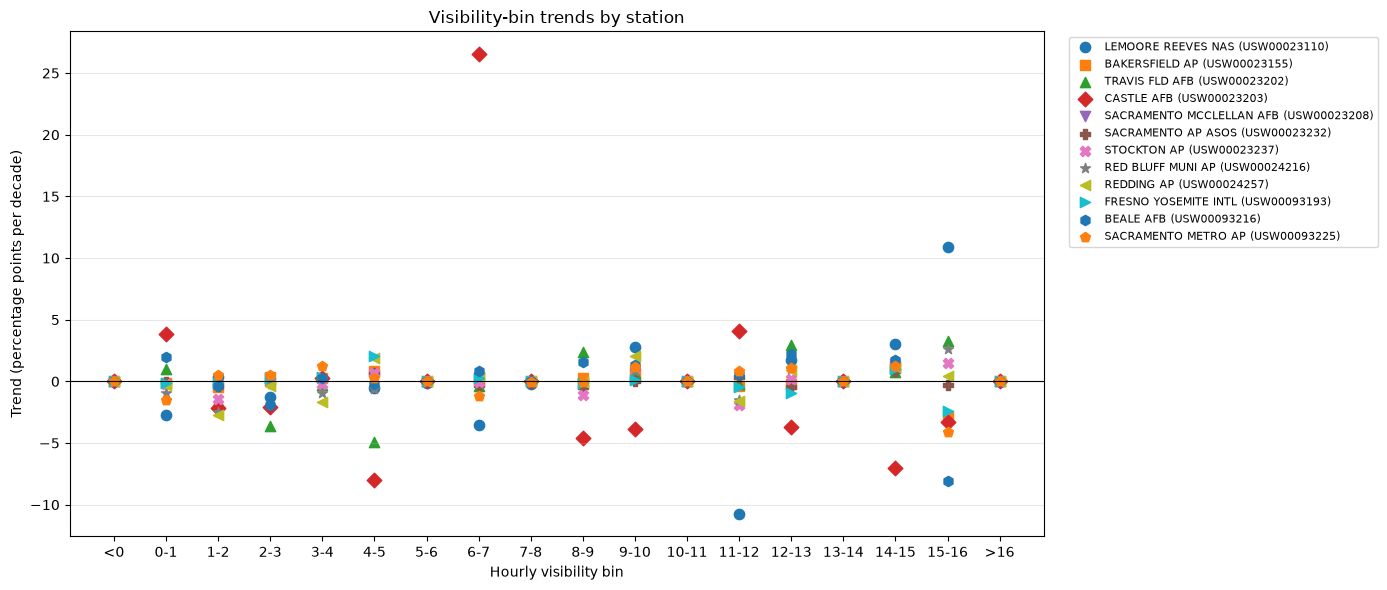

In [11]:
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', '<', '>', 'h', 'p', '8']
x = np.arange(len(bin_labels))

fig, ax = plt.subplots(figsize=(14, 6))

for i, station in enumerate(station_labels):
    ax.scatter(
        x,
        slope_matrix[i],
        marker=markers[i % len(markers)],
        label=station,
        s=55
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(bin_labels)
ax.set_xlabel('Hourly visibility bin')
ax.set_ylabel('Trend (percentage points per decade)')
ax.set_title('Visibility-bin trends by station')
ax.grid(axis='y', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

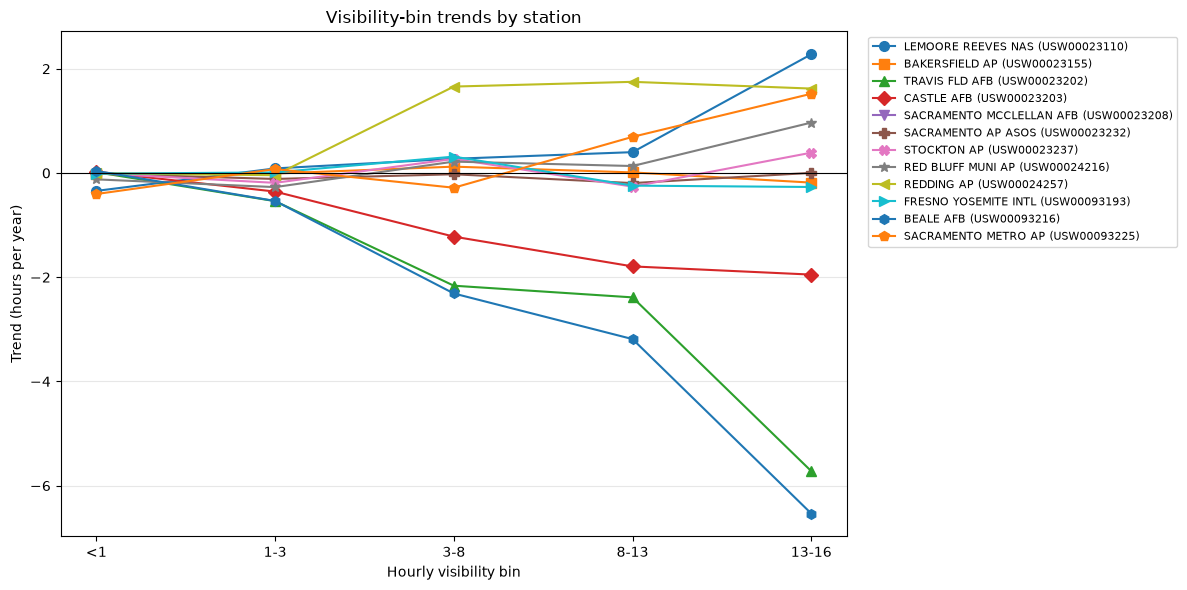

In [12]:
# New visibility bins: <1, 1-3, 3-8, 8-13, 13-16 (hours per year trends)
new_bin_labels = ['<1', '1-3', '3-8', '8-13', '13-16']
new_bin_edges = [-np.inf, 1, 3, 8, 13, np.inf]

vis_data = CV_precip_rows.dropna(
    subset=['HourlyVisibility', 'year', 'STATION_ID']
).copy()

vis_data['VisBin'] = pd.cut(
    vis_data['HourlyVisibility'],
    bins=new_bin_edges,
    labels=new_bin_labels,
    right=False
)

# Include exactly 16 in the 13-16 bin (already covered since upper edge is inf)
trend_labels = []
trend_slopes = []

for (station_id, station_name), sdata in vis_data.groupby(['STATION_ID', 'STATION'], sort=True):
    trend_labels.append(f'{station_name} ({station_id})')

    # Annual counts (hours per year) per bin
    annual_counts = (
        sdata.groupby(['year', 'VisBin'], observed=False)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=new_bin_labels, fill_value=0)
    )

    # Fill in missing years with zero hours
    all_years = np.arange(annual_counts.index.min(), annual_counts.index.max() + 1)
    annual_counts = annual_counts.reindex(all_years, fill_value=0)

    row_slopes = []
    for b in new_bin_labels:
        if len(annual_counts) >= 2:
            res = stats.linregress(
                annual_counts.index.to_numpy(dtype=float),
                annual_counts[b].to_numpy(dtype=float)
            )
            row_slopes.append(res.slope)  # hours per year
        else:
            row_slopes.append(np.nan)
    trend_slopes.append(row_slopes)

trend_slopes = np.asarray(trend_slopes, dtype=float)

# Plot
x_new = np.arange(len(new_bin_labels))
fig, ax = plt.subplots(figsize=(12, 6))

for i, station in enumerate(trend_labels):
    ax.plot(
        x_new,
        trend_slopes[i],
        marker=markers[i % len(markers)],
        linestyle='-',
        label=station,
        markersize=7
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x_new)
ax.set_xticklabels(new_bin_labels)
ax.set_xlabel('Hourly visibility bin')
ax.set_ylabel('Trend (hours per year)')
ax.set_title('Visibility-bin trends by station')
ax.grid(axis='y', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

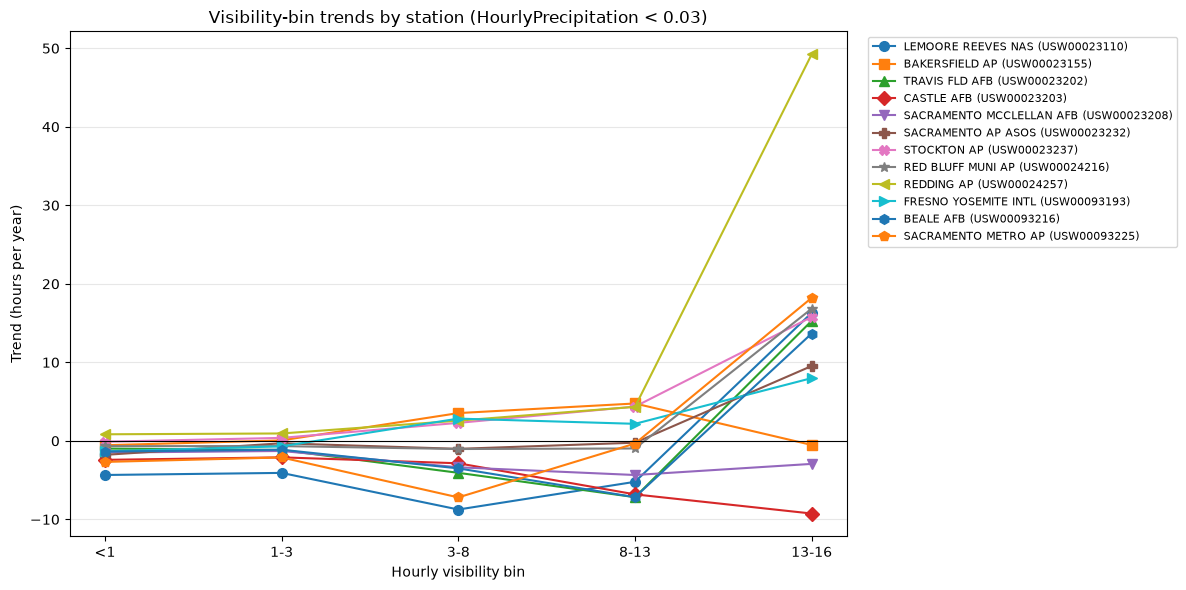

Slopes (hours per year):


,<1,1-3,3-8,8-13,13-16
LEMOORE REEVES NAS (USW00023110),-4.347640,-4.082080,-8.746241,-5.217657,16.304808
BAKERSFIELD AP (USW00023155),-0.559749,0.060115,3.536299,4.759539,-0.523854
TRAVIS FLD AFB (USW00023202),-0.982872,-1.161601,-4.072646,-7.175538,15.285001
CASTLE AFB (USW00023203),-2.420492,-2.102298,-2.857305,-6.817708,-9.257791
SACRAMENTO MCCLELLAN AFB (USW00023208),-1.493348,-1.292046,-3.367117,-4.350459,-2.934552
SACRAMENTO AP ASOS (USW00023232),-1.785470,-0.308497,-1.018533,-0.233483,9.535694
STOCKTON AP (USW00023237),-0.112351,0.378054,2.290620,4.358530,15.783174
RED BLUFF MUNI AP (USW00024216),-0.673872,-0.670573,-1.041080,-0.970547,16.837774
REDDING AP (USW00024257),0.835831,0.940205,2.569672,4.333224,49.233922
FRESNO YOSEMITE INTL (USW00093193),-1.333105,-0.695407,2.832089,2.169103,7.989291


P-values:


,<1,1-3,3-8,8-13,13-16
LEMOORE REEVES NAS (USW00023110),7.334741e-10,2.772876e-09,8.608641e-09,2.193310e-01,1.953912e-03
BAKERSFIELD AP (USW00023155),5.024074e-02,8.690117e-01,5.637543e-06,7.320276e-08,7.976234e-01
TRAVIS FLD AFB (USW00023202),2.649814e-02,2.813227e-03,1.704939e-08,1.771564e-13,3.232431e-11
CASTLE AFB (USW00023203),3.194273e-05,8.708034e-04,2.543665e-02,7.915989e-05,1.922453e-03
SACRAMENTO MCCLELLAN AFB (USW00023208),1.967806e-04,3.764285e-03,2.916511e-05,1.501250e-03,3.962479e-01
SACRAMENTO AP ASOS (USW00023232),1.049951e-07,3.119796e-01,1.557601e-01,6.856956e-01,2.018682e-06
STOCKTON AP (USW00023237),8.298765e-01,3.496731e-01,1.432196e-02,2.075162e-05,1.750392e-07
RED BLUFF MUNI AP (USW00024216),1.351030e-02,1.157504e-05,1.857875e-03,4.578858e-02,1.008754e-05
REDDING AP (USW00024257),1.206569e-05,2.770204e-07,4.673215e-09,3.786486e-13,3.468221e-33
FRESNO YOSEMITE INTL (USW00093193),7.012495e-03,1.783110e-01,9.653906e-03,6.168416e-02,2.109774e-04


In [13]:
# Trends in visibility bins (hours per year) for non-precipitation rows (HourlyPrecipitation < 0.03)
CV_noprecip_rows = CV_rows[CV_rows['HourlyPrecipitation'] < 0.03]

vis_data_np = CV_noprecip_rows.dropna(
    subset=['HourlyVisibility', 'year', 'STATION_ID']
).copy()

vis_data_np['VisBin'] = pd.cut(
    vis_data_np['HourlyVisibility'],
    bins=new_bin_edges,
    labels=new_bin_labels,
    right=False
)

trend_labels_np = []
trend_slopes_np = []
trend_pvalues_np = []

for (station_id, station_name), sdata in vis_data_np.groupby(['STATION_ID', 'STATION'], sort=True):
    trend_labels_np.append(f'{station_name} ({station_id})')

    annual_counts = (
        sdata.groupby(['year', 'VisBin'], observed=False)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=new_bin_labels, fill_value=0)
    )

    # Fill in missing years with zero hours
    all_years = np.arange(annual_counts.index.min(), annual_counts.index.max() + 1)
    annual_counts = annual_counts.reindex(all_years, fill_value=0)

    row_slopes = []
    row_pvalues = []
    for b in new_bin_labels:
        if len(annual_counts) >= 2:
            res = stats.linregress(
                annual_counts.index.to_numpy(dtype=float),
                annual_counts[b].to_numpy(dtype=float)
            )
            row_slopes.append(res.slope)  # hours per year
            row_pvalues.append(res.pvalue)
        else:
            row_slopes.append(np.nan)
            row_pvalues.append(np.nan)
    trend_slopes_np.append(row_slopes)
    trend_pvalues_np.append(row_pvalues)

trend_slopes_np = np.asarray(trend_slopes_np, dtype=float)
trend_pvalues_np = np.asarray(trend_pvalues_np, dtype=float)

# Plot
fig, ax = plt.subplots(figsize=(12, 6))

for i, station in enumerate(trend_labels_np):
    ax.plot(
        x_new,
        trend_slopes_np[i],
        marker=markers[i % len(markers)],
        linestyle='-',
        label=station,
        markersize=7
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x_new)
ax.set_xticklabels(new_bin_labels)
ax.set_xlabel('Hourly visibility bin')
ax.set_ylabel('Trend (hours per year)')
ax.set_title('Visibility-bin trends by station (HourlyPrecipitation < 0.03)')
ax.grid(axis='y', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

# Summary table of slopes and p-values
slopes_df = pd.DataFrame(trend_slopes_np, index=trend_labels_np, columns=new_bin_labels)
pvalues_df = pd.DataFrame(trend_pvalues_np, index=trend_labels_np, columns=new_bin_labels)
print("Slopes (hours per year):")
display(slopes_df)
print("P-values:")
display(pvalues_df)

C:\Users\Work Account\AppData\Local\Temp\ipykernel_6724\598223695.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


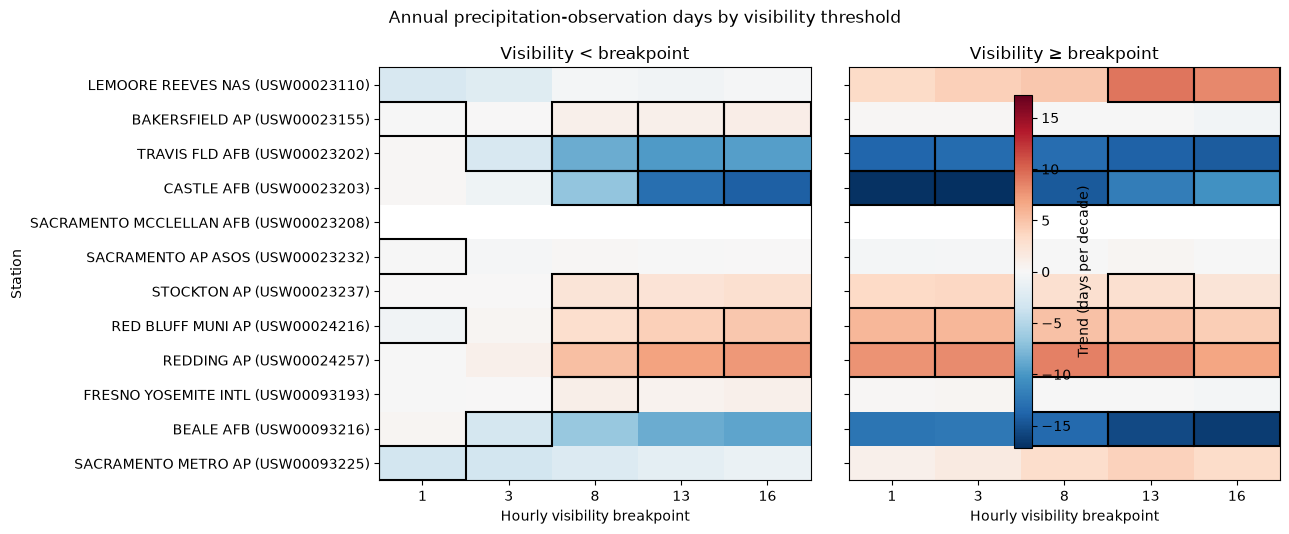

In [14]:
visibility_breakpoints = [1, 3, 8, 13, 16]

precip_vis = CV_precip_rows.dropna(
    subset=['HourlyVisibility', 'year', 'STATION_ID', 'STATION', 'DATE']
).copy()
precip_vis['DateOnly'] = pd.to_datetime(precip_vis['DATE']).dt.normalize()

station_labels_trend = []
slopes_below, pvalues_below = [], []
slopes_above, pvalues_above = [], []

for (station_id, station_name), station_data in precip_vis.groupby(
    ['STATION_ID', 'STATION'], sort=True
):
    station_labels_trend.append(f'{station_name} ({station_id})')

    years = np.arange(
        int(station_data['year'].min()),
        int(station_data['year'].max()) + 1
    )

    station_below_slopes, station_below_p = [], []
    station_above_slopes, station_above_p = [], []

    for breakpoint in visibility_breakpoints:
        for condition, slope_list, pvalue_list in [
            (station_data['HourlyVisibility'] < breakpoint,
             station_below_slopes, station_below_p),
            (station_data['HourlyVisibility'] >= breakpoint,
             station_above_slopes, station_above_p)
        ]:
            qualifying_days = station_data.loc[
                condition, ['year', 'DateOnly']
            ].drop_duplicates()

            annual_days = (
                qualifying_days.groupby('year').size()
                .reindex(years, fill_value=0)
            )

            if len(years) >= 2:
                fit = stats.linregress(years.astype(float), annual_days.to_numpy())
                slope_list.append(fit.slope * 10)  # days per decade
                pvalue_list.append(fit.pvalue)
            else:
                slope_list.append(np.nan)
                pvalue_list.append(np.nan)

    slopes_below.append(station_below_slopes)
    pvalues_below.append(station_below_p)
    slopes_above.append(station_above_slopes)
    pvalues_above.append(station_above_p)

slopes_below = np.asarray(slopes_below, dtype=float)
pvalues_below = np.asarray(pvalues_below, dtype=float)
slopes_above = np.asarray(slopes_above, dtype=float)
pvalues_above = np.asarray(pvalues_above, dtype=float)

max_abs_slope = np.nanmax(np.abs([slopes_below, slopes_above]))
if not np.isfinite(max_abs_slope) or max_abs_slope == 0:
    max_abs_slope = 1

fig, axes = plt.subplots(
    1, 2, figsize=(13, max(4, 0.45 * len(station_labels_trend))),
    sharey=True
)

for ax, slope_data, pvalue_data, title in [
    (axes[0], slopes_below, pvalues_below, 'Visibility < breakpoint'),
    (axes[1], slopes_above, pvalues_above, 'Visibility ≥ breakpoint')
]:
    image = ax.imshow(
        slope_data, aspect='auto', cmap='RdBu_r',
        vmin=-max_abs_slope, vmax=max_abs_slope
    )
    ax.set_xticks(np.arange(len(visibility_breakpoints)))
    ax.set_xticklabels(visibility_breakpoints)
    ax.set_xlabel('Hourly visibility breakpoint')
    ax.set_title(title)

    for row, col in zip(*np.where(pvalue_data < 0.05)):
        ax.add_patch(plt.Rectangle(
            (col - 0.5, row - 0.5), 1, 1,
            fill=False, edgecolor='black', linewidth=1.5
        ))

axes[0].set_yticks(np.arange(len(station_labels_trend)))
axes[0].set_yticklabels(station_labels_trend)
axes[0].set_ylabel('Station')

colorbar = fig.colorbar(image, ax=axes, shrink=0.85)
colorbar.set_label('Trend (days per decade)')
fig.suptitle('Annual precipitation-observation days by visibility threshold')
plt.tight_layout()
plt.show()

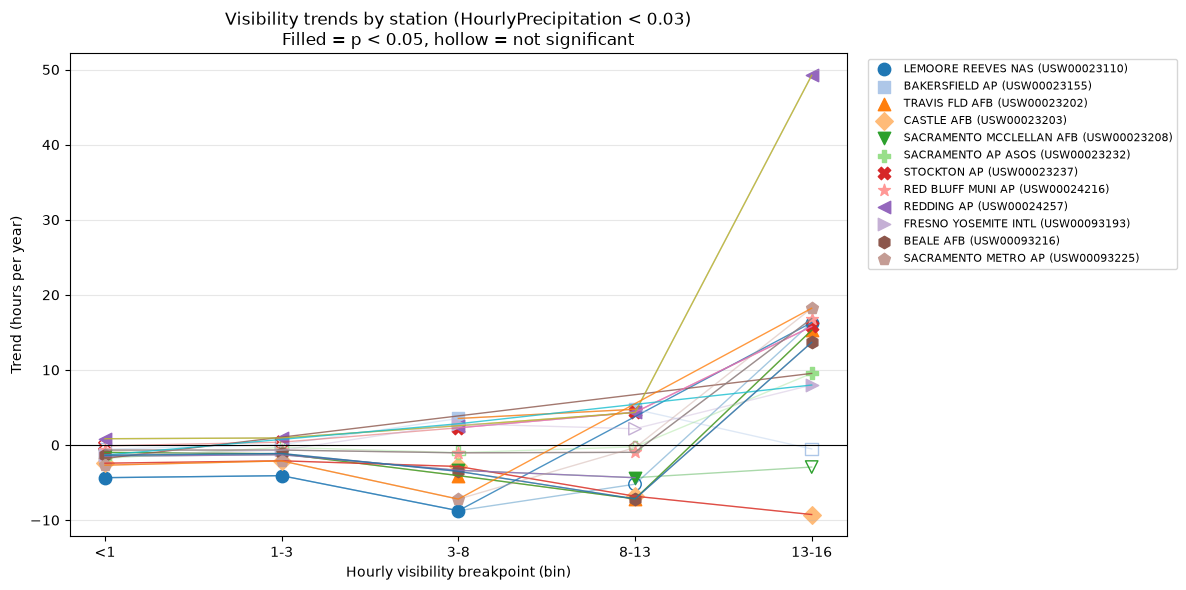

In [17]:
fig, ax = plt.subplots(figsize=(12, 6))
cmap = plt.get_cmap('tab20')
#Outline datapoints for significant trends in black for each station

for i, station in enumerate(trend_labels_np):
    significant = trend_pvalues_np[i] < 0.05
    color = cmap(i % 20)
    marker = markers[i % len(markers)]

    # Connecting line
    ax.plot(x_new, trend_slopes_np[i], color=color, alpha=0.4, linewidth=1)
    ax.plot(x_new[significant], trend_slopes_np[i][significant], alpha=0.8, linewidth=1)

    # Significant points filled, non-significant hollow
    ax.scatter(
        x_new[significant], trend_slopes_np[i][significant],
        marker=marker, color=color, s=80, label=station
    )
    ax.scatter(
        x_new[~significant], trend_slopes_np[i][~significant],
        marker=marker, facecolors='none', edgecolors=color, s=80
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x_new)
ax.set_xticklabels(new_bin_labels)
ax.set_xlabel('Hourly visibility breakpoint (bin)')
ax.set_ylabel('Trend (hours per year)')
ax.set_title('Visibility trends by station (HourlyPrecipitation < 0.03)\nFilled = p < 0.05, hollow = not significant')
ax.grid(axis='y', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

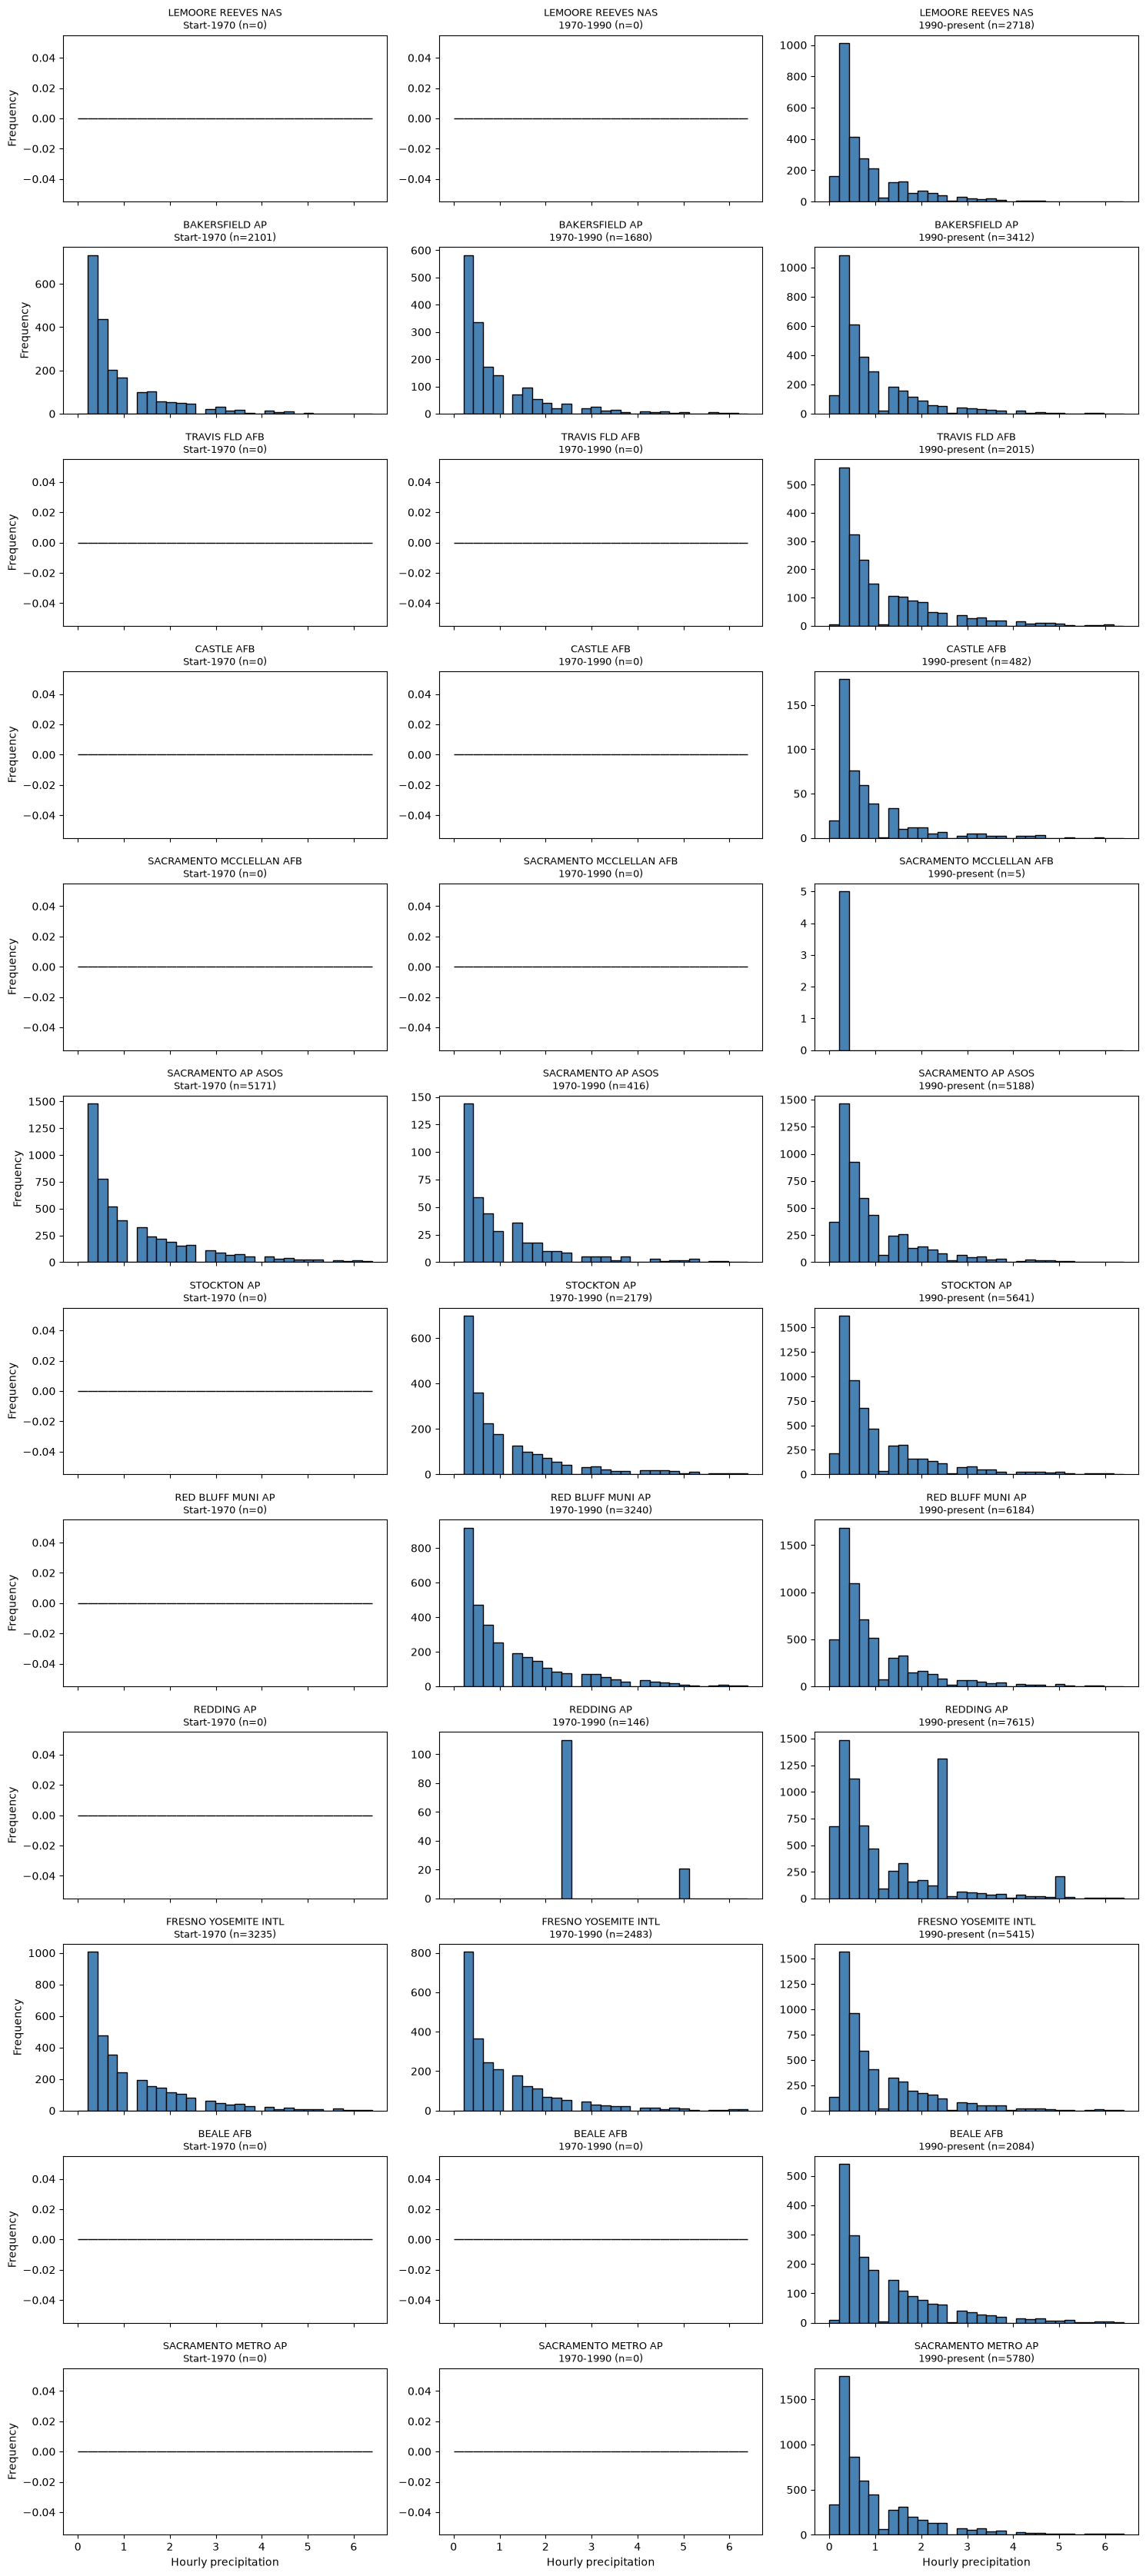

In [19]:
# Histograms of HourlyPrecipitation >= 0.001 per station for three periods
periods = [
    ('Start-1970', CV_precip_rows['year'] <= 1970),
    ('1970-1990', (CV_precip_rows['year'] > 1970) & (CV_precip_rows['year'] <= 1990)),
    ('1990-present', CV_precip_rows['year'] > 1990),
]

stations = (
    CV_precip_rows[['STATION_ID', 'STATION']]
    .drop_duplicates()
    .sort_values('STATION_ID')
)

# Common bins so periods are comparable
max_precip = CV_precip_rows['HourlyPrecipitation'].quantile(0.99)
hist_bins = np.linspace(0.001, max_precip, 31)

n_stations = len(stations)
ncols = 3
fig, axes = plt.subplots(
    n_stations, ncols, figsize=(15, 2.8 * n_stations),
    sharex=True, squeeze=False
)

for i, (station_id, station_name) in enumerate(stations.itertuples(index=False)):
    station_df = CV_precip_rows[CV_precip_rows['STATION_ID'] == station_id]
    for j, (label, mask) in enumerate(periods):
        ax = axes[i, j]
        vals = station_df.loc[mask.reindex(station_df.index), 'HourlyPrecipitation'].dropna()
        ax.hist(vals, bins=hist_bins, color='steelblue', edgecolor='black')
        ax.set_title(f'{station_name}\n{label} (n={len(vals)})', fontsize=9)
        if j == 0:
            ax.set_ylabel('Frequency')
        if i == n_stations - 1:
            ax.set_xlabel('Hourly precipitation')

plt.tight_layout()
plt.show()

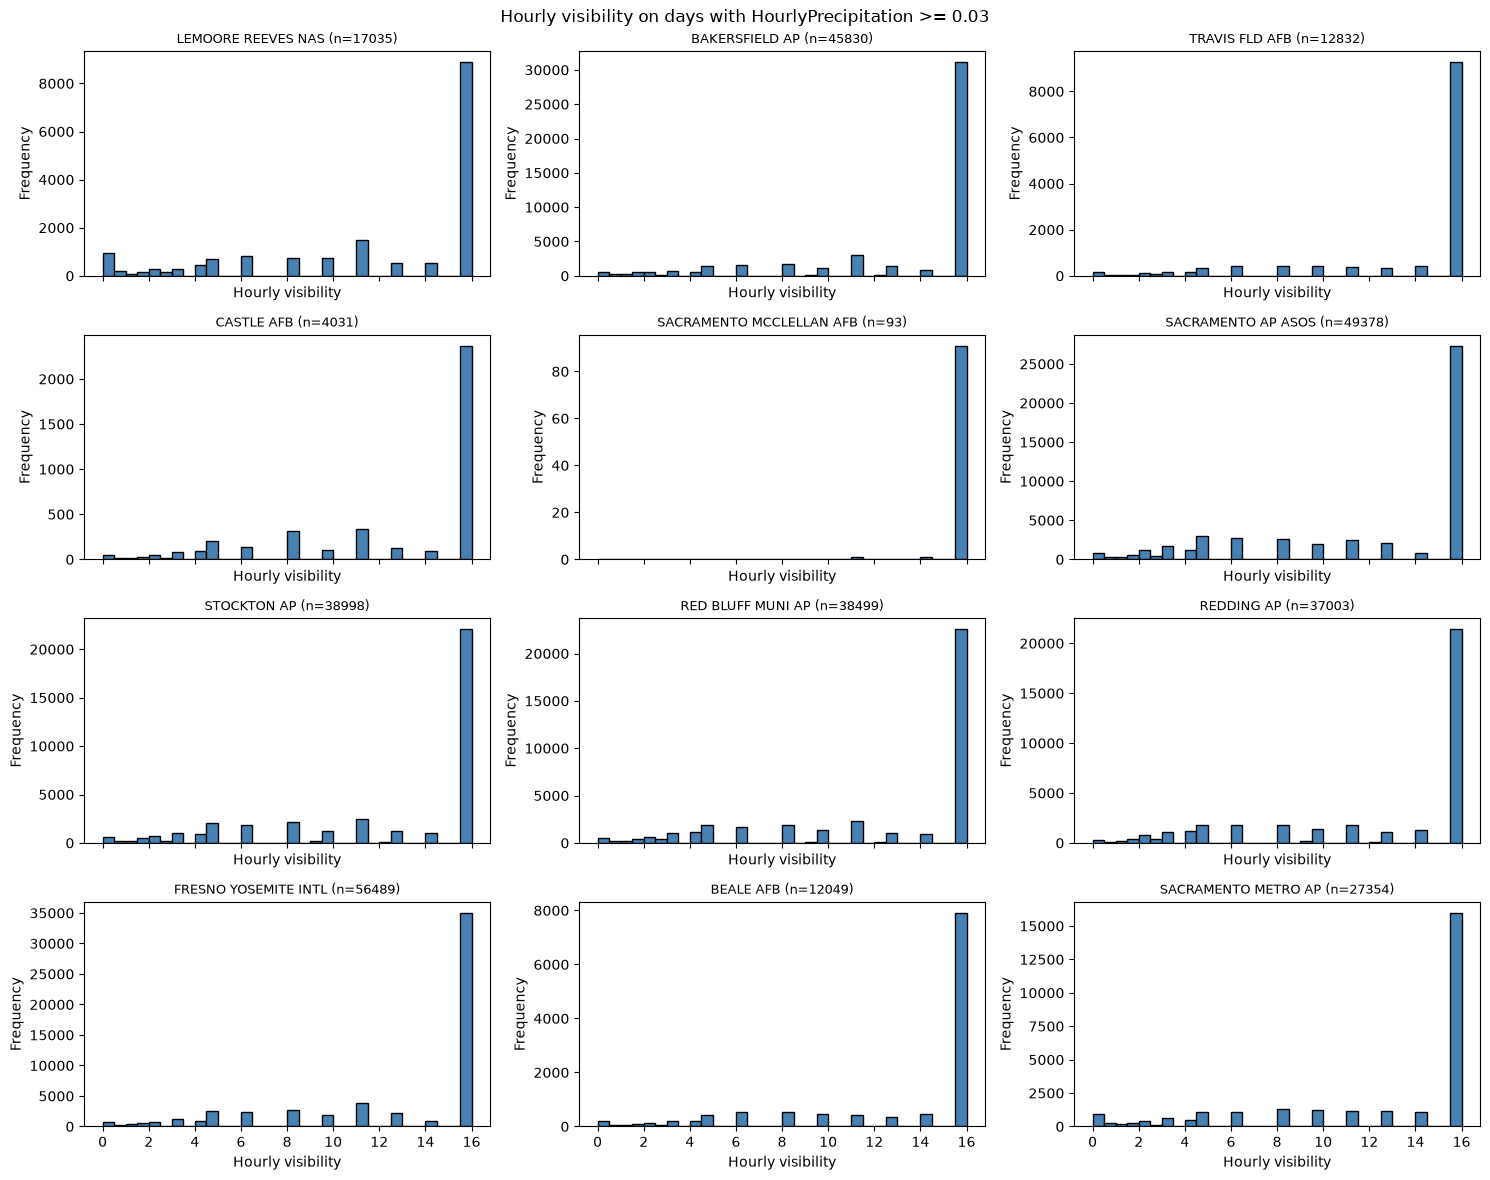

In [20]:
# Select all observations on days with at least one HourlyPrecipitation >= 0.03
day_df = CV_rows.copy()
day_df['DateOnly'] = pd.to_datetime(day_df['DATE']).dt.normalize()

precip_days = (
    CV_precip_rows.assign(DateOnly=pd.to_datetime(CV_precip_rows['DATE']).dt.normalize())
    [['STATION_ID', 'DateOnly']]
    .drop_duplicates()
)

precip_day_rows = day_df.merge(precip_days, on=['STATION_ID', 'DateOnly'], how='inner')
precip_day_rows = precip_day_rows.dropna(subset=['HourlyVisibility'])

# Histograms of HourlyVisibility per station
vis_bins = np.linspace(0, 16, 33)
n_stations = len(stations)
ncols = 3
nrows = int(np.ceil(n_stations / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3 * nrows), sharex=True, squeeze=False)

for ax, (station_id, station_name) in zip(axes.flat, stations.itertuples(index=False)):
    vals = precip_day_rows.loc[precip_day_rows['STATION_ID'] == station_id, 'HourlyVisibility']
    ax.hist(vals, bins=vis_bins, color='steelblue', edgecolor='black')
    ax.set_title(f'{station_name} (n={len(vals)})', fontsize=9)
    ax.set_xlabel('Hourly visibility')
    ax.set_ylabel('Frequency')

# Hide unused axes
for ax in axes.flat[n_stations:]:
    ax.set_visible(False)

fig.suptitle('Hourly visibility on days with HourlyPrecipitation >= 0.03')
plt.tight_layout()
plt.show()

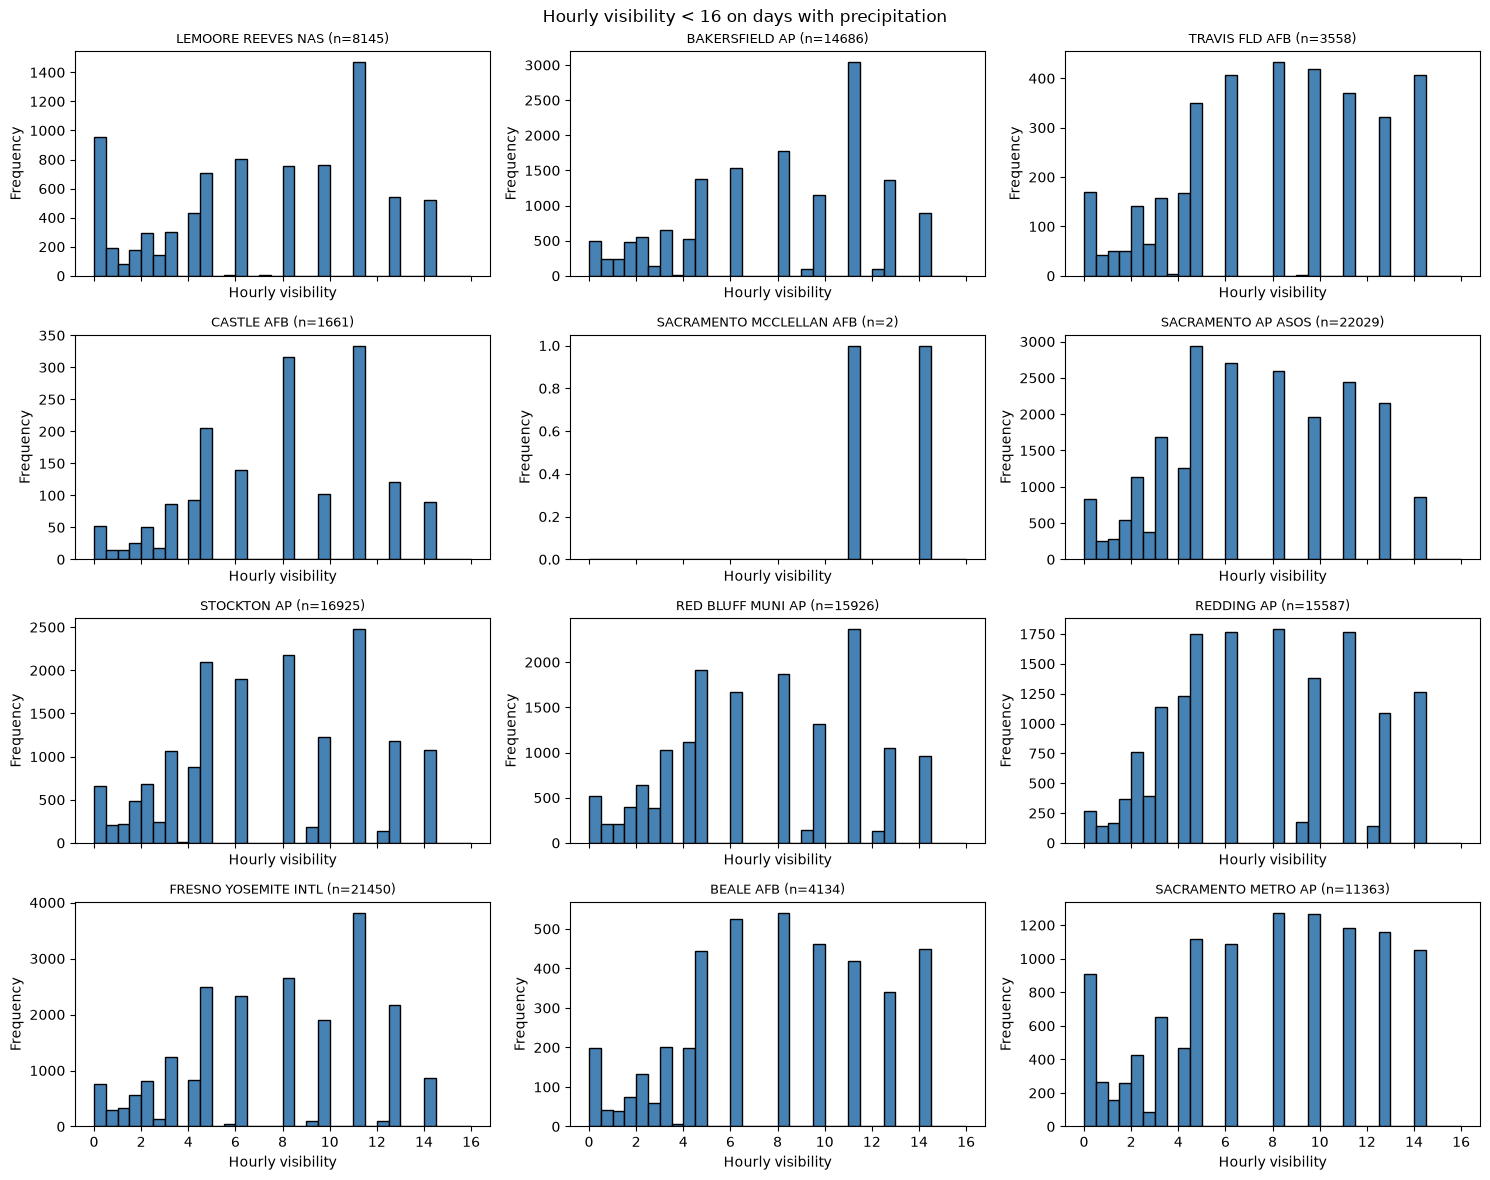

In [21]:
# Exclude visibility values >= 16, then replot histograms by station
precip_day_rows_lt16 = precip_day_rows[
    precip_day_rows['HourlyVisibility'] < 16
].copy()

n_stations = len(stations)
ncols = 3
nrows = int(np.ceil(n_stations / ncols))

vis_bins_lt16 = np.linspace(0, 16, 33)
fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 3 * nrows), sharex=True, squeeze=False
)

for ax, (station_id, station_name) in zip(
    axes.flat, stations.itertuples(index=False)
):
    vals = precip_day_rows_lt16.loc[
        precip_day_rows_lt16['STATION_ID'] == station_id, 'HourlyVisibility'
    ].dropna()

    ax.hist(vals, bins=vis_bins_lt16, color='steelblue', edgecolor='black')
    ax.set_title(f'{station_name} (n={len(vals)})', fontsize=9)
    ax.set_xlabel('Hourly visibility')
    ax.set_ylabel('Frequency')

for ax in axes.flat[n_stations:]:
    ax.set_visible(False)

fig.suptitle('Hourly visibility < 16 on days with precipitation')
plt.tight_layout()
plt.show()